In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import xgboost as xgb
import shap

sns.set_theme(style='whitegrid')
print('Libraries loaded')

Libraries loaded


/Users/dwr/code/recursive-leverage-defi/analysis/whale-risk-supervised/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
df = pd.read_csv('whale_features_labeled.csv', parse_dates=['date'])

print(f'Shape: {df.shape}')
print(f'Whales: {df["whale_id"].unique()}')

Shape: (2507, 40)
Whales: <StringArray>
[ 'W-1', 'W-10', 'W-11', 'W-12', 'W-13', 'W-14', 'W-15', 'W-16', 'W-17',
 'W-18', 'W-19',  'W-2', 'W-20', 'W-21', 'W-22', 'W-23', 'W-24',  'W-3',
  'W-4',  'W-5',  'W-6',  'W-7',  'W-8',  'W-9']
Length: 24, dtype: str


In [3]:
FEATURES = [
    'ltv_vol_7d',
    'ltv_vol_14d',
    'carry_spread',
    'carry_spread_levered',
    'ybt_apy',
    'borrow_rate',
    'supply_rate',
    'collateral_price',
    'borrow_price',
]

TARGET = 'stressed_state'



print(f'Features: {len(FEATURES)}')
print(f'Target: {TARGET}')
print(f'\nTarget distribution:')
print(df[TARGET].value_counts())
print(f'\nStressed rate: {df[TARGET].mean():.1%}')

Features: 9
Target: stressed_state

Target distribution:
stressed_state
0    1782
1     725
Name: count, dtype: int64

Stressed rate: 28.9%


Target Distribution

Out of 2,507 total days:

1,782 days: whale was not stressed (0)
725 days: whale was in a stressed state (1)

Overall stressed rate is 28.9 percent, so roughly 1 in 3 days across all whales was a stressed day.

This is mildly imbalanced.

We predict stressed_state, which tells us whether a whale is in a stressed risk position on a given day. 1 means stressed, 0 means not stressed.

11 features are used:

ltv_vol_7d and ltv_vol_14d show how much the leverage has been moving around recently, over the past 7 and 14 days.

carry_spread and carry_spread_levered are the yield earned minus the cost of borrowing.

ybt_apy, borrow_rate, and supply_rate are the yield and interest rate numbers for the position.

collateral_price and borrow_price show how the market price of each token has been moving.

collateral_balance and borrow_balance are the raw amount of tokens held and borrowed.

Features excluded and why:

ltv, ltv_lag_1, ltv_lag_3, ltv_lag_7, health_factor, distance_to_liq, and loop_depth were all removed. These are either the same number as health_factor written a different way, or they were used to calculate it, or they were used to define stressed_state directly. Including any of these would let the model see the answer instead of learning from real patterns. This is called data leakage.

collateral_balance_usd, borrow_balance_usd, and liquidation_threshold were also removed for the same reason, since ltv is built directly from these numbers.

rebal_freq_7d, rebal_freq_30d, and days_since_rebalance were left out too. These are related to a different target, rebalancing, and are not meaningful for predicting stress.

rebalancing itself is a separate target variable, not a feature, so it is not included here either.

In [4]:
data = df.dropna(subset=FEATURES + [TARGET])

X = data[FEATURES]
y = data[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

print(f'Train: {X_train.shape} | Stressed rate: {y_train.mean():.1%}')
print(f'Test:  {X_test.shape}  | Stressed rate: {y_test.mean():.1%}')

Train: (1463, 9) | Stressed rate: 31.6%
Test:  (628, 9)  | Stressed rate: 31.7%


In [5]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

lr = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
lr.fit(X_train_scaled, y_train)
y_pred_lr = lr.predict(X_test_scaled)

print('=== Logistic Regression (Baseline) ===')
print(classification_report(y_test, y_pred_lr))
print(f'ROC-AUC: {roc_auc_score(y_test, lr.predict_proba(X_test_scaled)[:,1]):.3f}')

y_pred_lr_tuned = (lr.predict_proba(X_test_scaled)[:,1] >= 0.3).astype(int)

print('=== Logistic Regression (threshold=0.3) ===')
print(classification_report(y_test, y_pred_lr_tuned))
print(f'ROC-AUC: {roc_auc_score(y_test, lr.predict_proba(X_test_scaled)[:,1]):.3f}')

=== Logistic Regression (Baseline) ===
              precision    recall  f1-score   support

           0       0.98      0.85      0.91       429
           1       0.75      0.95      0.84       199

    accuracy                           0.89       628
   macro avg       0.86      0.90      0.88       628
weighted avg       0.90      0.89      0.89       628

ROC-AUC: 0.971
=== Logistic Regression (threshold=0.3) ===
              precision    recall  f1-score   support

           0       0.99      0.78      0.87       429
           1       0.67      0.98      0.80       199

    accuracy                           0.84       628
   macro avg       0.83      0.88      0.83       628
weighted avg       0.89      0.84      0.85       628

ROC-AUC: 0.971


In [6]:
xgb_model = xgb.XGBClassifier(
    n_estimators=50,
    max_depth=2,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=5,
    random_state=42,
    eval_metric='logloss',
    verbosity=0
)

xgb_model.fit(X_train, y_train)

y_pred_xgb = (xgb_model.predict_proba(X_test)[:,1] >= 0.3).astype(int)

print('=== XGBoost (threshold=0.3) ===')
print(classification_report(y_test, y_pred_xgb))
print(f'ROC-AUC: {roc_auc_score(y_test, xgb_model.predict_proba(X_test)[:,1]):.3f}')

y_pred_xgb_default = xgb_model.predict(X_test)

print('=== XGBoost (threshold=0.5 default) ===')
print(classification_report(y_test, y_pred_xgb_default))
print(f'ROC-AUC: {roc_auc_score(y_test, xgb_model.predict_proba(X_test)[:,1]):.3f}')

=== XGBoost (threshold=0.3) ===
              precision    recall  f1-score   support

           0       0.95      0.90      0.93       429
           1       0.81      0.90      0.86       199

    accuracy                           0.90       628
   macro avg       0.88      0.90      0.89       628
weighted avg       0.91      0.90      0.90       628

ROC-AUC: 0.977
=== XGBoost (threshold=0.5 default) ===
              precision    recall  f1-score   support

           0       0.92      0.97      0.95       429
           1       0.93      0.82      0.87       199

    accuracy                           0.92       628
   macro avg       0.92      0.90      0.91       628
weighted avg       0.92      0.92      0.92       628

ROC-AUC: 0.977


Model Comparison, Stressed State Prediction

We tested two models, Logistic Regression and XGBoost, at two decision thresholds, 0.5 (default) and 0.3, to find the best approach for predicting stressed risk states.

| Model | Threshold | Recall | Precision | ROC-AUC | Accuracy |
|---|---|---|---|---|---|
| Logistic Regression | 0.5 | 0.95 | 0.75 | 0.971 | 89% |
| Logistic Regression | 0.3 | 0.98 | 0.67 | 0.971 | 84% |
| XGBoost | 0.5 | 0.82 | 0.93 | 0.977 | 92% |
| XGBoost | 0.3 | 0.90 | 0.81 | 0.977 | 90% |

Why threshold 0.3?

By default, a model predicts stressed only when it is more than 50 percent confident. Lowering the threshold to 0.3 means the model raises an alarm when it is only 30 percent confident. This catches more stressed days, but it also means more false alarms.

In a risk management setting, missing a stressed day is usually more costly than a false alarm, since a missed stressed day could mean a whale gets liquidated. So lowering the threshold can be a reasonable choice, depending on how much you value catching more events versus keeping false alarms low.

Why XGBoost?

XGBoost is the stronger model at both thresholds. At the default threshold of 0.5, it catches 82 percent of stressed days and is right 93 percent of the time when it predicts stress, with an accuracy of 92 percent. This is a very precise model, with few false alarms.

At threshold 0.3, XGBoost catches more stressed days, 90 percent, while still keeping precision at a solid 81 percent. Accuracy stays high at 90 percent.

Logistic Regression at threshold 0.3 catches slightly more stressed days, 98 percent, but its precision drops to 67 percent. This means many of its stress predictions are false alarms.

Overall, XGBoost gives the better balance at both thresholds. It is more precise than Logistic Regression while still catching most stressed days, and its ROC-AUC of 0.977 confirms it separates stressed from non-stressed days more reliably.

If catching as many stressed days as possible matters most, XGBoost at threshold 0.3 is the best choice, since it keeps precision reasonably high while catching 90 percent of real events. If keeping false alarms very low matters more, XGBoost at the default threshold of 0.5 is the safer option.

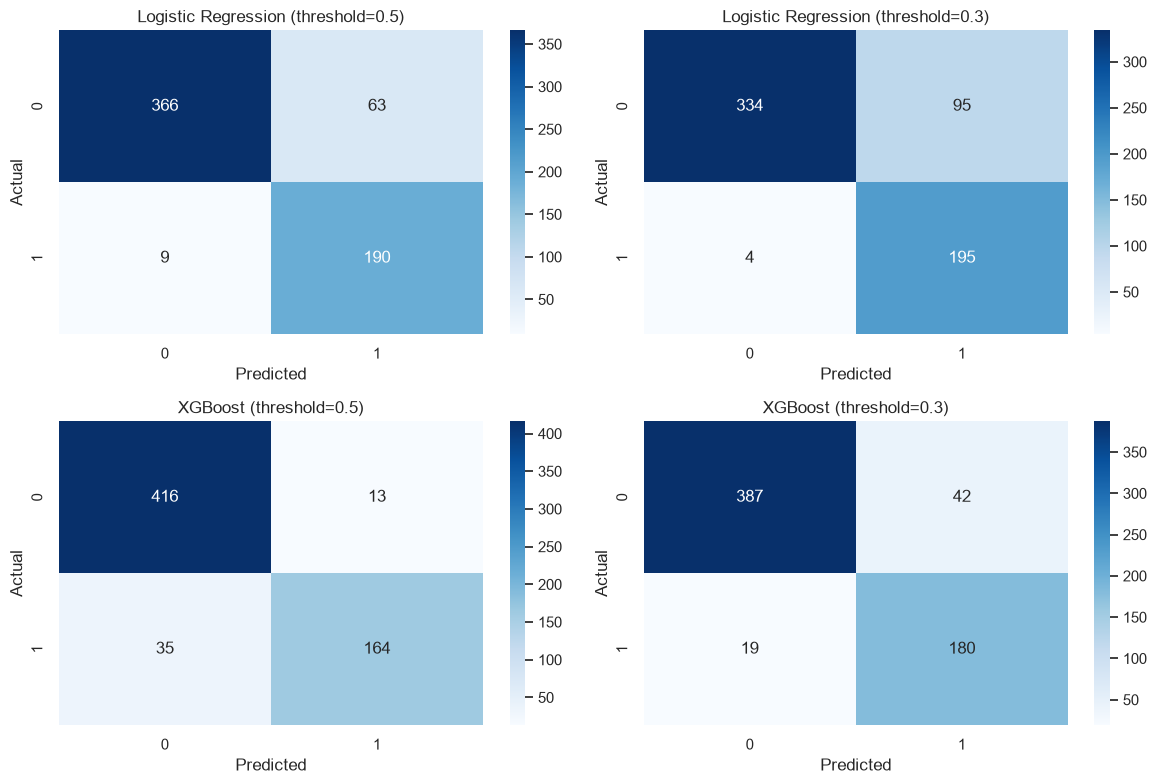

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

variants = [
    (y_pred_lr, 'Logistic Regression (threshold=0.5)'),
    (y_pred_lr_tuned, 'Logistic Regression (threshold=0.3)'),
    (y_pred_xgb_default, 'XGBoost (threshold=0.5)'),
    (y_pred_xgb, 'XGBoost (threshold=0.3)'),
]

for ax, (preds, title) in zip(axes.flatten(), variants):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax)
    ax.set_title(title)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

Confusion Matrices, Stressed State Model

Each matrix shows how well the model predicts stressed days (1) versus non stressed days (0).

Top left: correctly predicted not stressed.
Top right: predicted stressed but was wrong. This is a false alarm.
Bottom left: missed a real stressed day. This is the dangerous case.
Bottom right: correctly predicted stressed.

Logistic Regression (threshold 0.5)

Caught 190 out of 199 stressed days. Missed 9.
Made 63 false alarms out of 429 non stressed days.
This means it misses about 1 in 22 stressed days, and it also raises a fair number of false alarms.

Logistic Regression (threshold 0.3)

Caught 195 out of 199 stressed days. Missed only 4.
But made 95 false alarms out of 429 non stressed days.
This catches almost every stressed day, but more than 1 in 5 normal days get wrongly flagged as stressed.

XGBoost (threshold 0.5)

Caught 164 out of 199 stressed days. Missed 35.
Made only 13 false alarms out of 429 non stressed days.
This is very precise, but it misses about 1 in 6 stressed days, since it only raises an alarm when it is quite confident.

XGBoost (threshold 0.3), best model

Caught 180 out of 199 stressed days. Missed only 19.
Made 42 false alarms out of 429 non stressed days.
This gives the best overall balance. It catches most stressed days while keeping false alarms much lower than either Logistic Regression option.

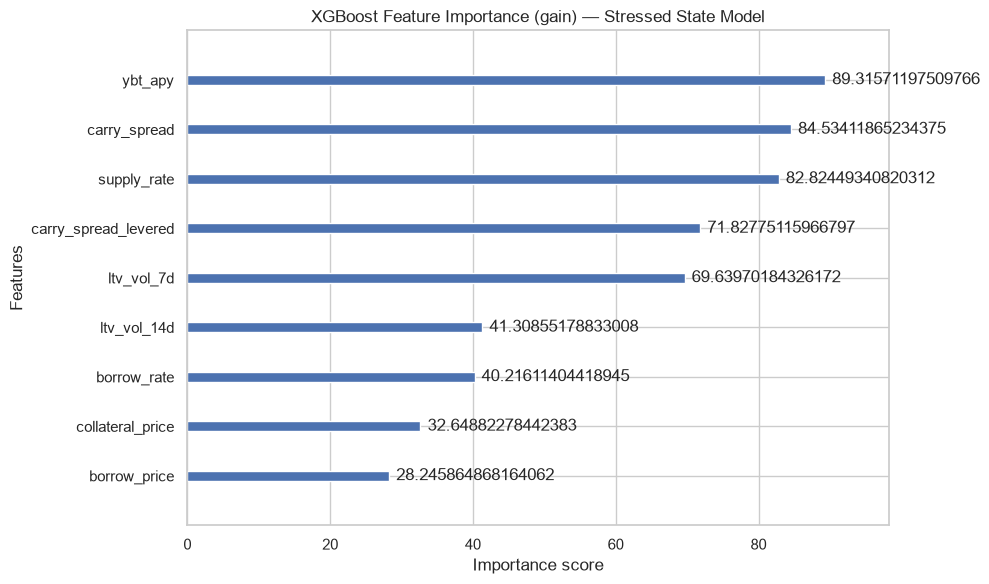

In [8]:
fig, ax = plt.subplots(figsize=(10, 6))
xgb.plot_importance(xgb_model, ax=ax, max_num_features=12, importance_type='gain')
ax.set_title('XGBoost Feature Importance (gain) — Stressed State Model')
plt.tight_layout()
plt.show()

XGBoost Feature Importance, Stressed State Model

This chart shows which features the model relied on most to predict stressed states. A higher score means the feature was more useful for making predictions.

Top features:

ybt_apy (89.3) is the strongest predictor of stress. This is the yield rate on the yield bearing token. This tells us that changes in yield are closely linked to whether a whale ends up stressed.

carry_spread (84.5) is the second most important. This is the yield earned minus the cost of borrowing. When this spread shrinks, a whale's position becomes less profitable, which seems to line up with stress.

supply_rate (82.8) is close behind. This is the rate earned on supplied assets, so it makes sense this moves closely with yield related stress too.

carry_spread_levered (71.8) also matters a lot. This is the same yield minus cost idea, but scaled up for leverage, so it makes sense it follows a similar pattern to carry_spread.

ltv_vol_7d (69.6) shows that how much leverage has moved around in the past week is still an important signal, just a bit less important than the yield related features.

Middle features:

ltv_vol_14d (41.3) and borrow_rate (40.2) both play a meaningful but smaller role. Longer term volatility and the cost of borrowing both add some signal, but less than the top group.

Lower features:

collateral_price (32.6) and borrow_price (28.2) are the least important, but they still contribute a reasonable amount. Neither one is close to zero, which is a good sign that the model is not relying on a single shortcut feature.

What this tells us:

Stress in this model seems to be driven mainly by yield and rate changes, more than by leverage swings alone. This makes sense, since a whale can still be in a risky position even if leverage looks stable, if the yield they are earning drops too close to their borrowing cost. The volatility features still matter, but they take a back seat to the yield and rate features here.

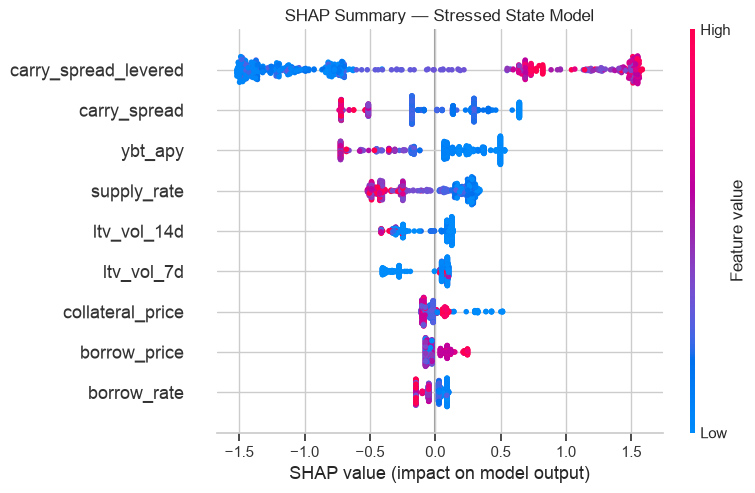

In [9]:
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test)

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test, feature_names=FEATURES, show=False)
plt.title('SHAP Summary — Stressed State Model')
plt.tight_layout()
plt.show()

SHAP Summary, Stressed State Model

Each dot is one day in the test set. The position on the x-axis shows how much that feature pushed the prediction toward stressed (right side) or away from it (left side). The color shows the feature value, where pink means high and blue means low.

Reading each feature:

carry_spread_levered is the top feature and has by far the widest spread, stretching from about -1.5 to 1.5. Blue dots (low value) sit far on the left, pushing away from stress. Pink and purple dots (high value) sit far on the right, pushing strongly toward stress. This shows that when the levered yield spread is high, the position is much more likely to be flagged as stressed, and when it is low, it strongly reduces the stress prediction.

carry_spread is the second feature. Pink dots (high spread) tend to sit on the left, pushing away from stress, while blue dots (low spread) spread further to the right, pushing toward stress. This is the opposite direction from carry_spread_levered, which is worth keeping in mind when reading the two together.

ybt_apy shows a fairly clean pattern too. Blue dots (low yield) push to the right toward stress, while pink and purple dots cluster more to the left. This suggests that lower yield tends to increase the chance of being marked stressed.

supply_rate follows a similar pattern to ybt_apy. Pink dots sit on the left, and blue dots spread further right, meaning lower supply rates are linked to a higher chance of stress.

ltv_vol_14d and ltv_vol_7d both have a smaller spread than the top features, staying mostly close to zero with a bit of a rightward pull. This means volatility in leverage still adds some signal, but less strongly than the yield related features.

collateral_price shows a mixed pattern, with both pink and blue dots on both sides, though blue dots stretch a bit further to the right. This suggests a smaller and less consistent effect.

borrow_price and borrow_rate both cluster tightly near zero, meaning they have very little effect on the model's predictions.

What this tells us:

Stress in this model seems to be driven mainly by yield and rate related features, especially carry_spread_levered, carry_spread, ybt_apy, and supply_rate. Leverage volatility still plays a role, but a smaller one. Price and borrow rate features barely move the prediction at all. This lines up with the feature importance chart, where the same yield and rate features came out on top.

In [91]:
results = data.loc[X_test.index].copy()
results['pred_stressed'] = y_pred_xgb
results['pred_proba_stressed'] = xgb_model.predict_proba(X_test)[:,1]
results[['whale_id', 'date', 'stressed_state', 'pred_stressed', 'pred_proba_stressed']].to_csv('predictions_stressed.csv', index=False)
print('Saved: predictions_stressed.csv')

Saved: predictions_stressed.csv
